```{raw} jupyter
<div id="qe-notebook-header" align="right" style="text-align:right;">
        <a href="https://quantecon.org/" title="quantecon.org">
                <img style="width:250px;display:inline;" width="250px" src="https://assets.quantecon.org/img/qe-menubar-logo.svg" alt="QuantEcon">
        </a>
</div>
```

# {index}`新冠病毒建模 <single: Modeling COVID-19>`

```{contents} Contents
:depth: 2
```

## 概述

这是由 [Andrew Atkeson](https://sites.google.com/site/andyatkeson/) 提供的用于分析新冠疫情的Python代码。

特别参见

* [NBER工作论文第26867号](https://www.nber.org/papers/w26867)
* [COVID-19工作论文和代码](https://sites.google.com/site/andyatkeson/home/covid-work)

他的这些笔记主要是介绍了定量建模传染病动态研究。

疾病传播使用标准SEIR（易感者-暴露者-感染者-移出者）模型进行建模。

模型动态用常微分方程组表示。

其主要目的是研究通过社交距离实施的抑制措施对感染传播的影响。

本课程主要模拟的是美国的结果，当然，也可以调整参数来研究其他国家。

我们将使用以下标准导入：

In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
FONTPATH = "fonts/SourceHanSerifSC-SemiBold.otf"
mpl.font_manager.fontManager.addfont(FONTPATH)
plt.rcParams['font.family'] = ['Source Han Serif SC']

import numpy as np
from numpy import exp

我们还将使用SciPy的数值例程odeint来求解微分方程。

In [2]:
from scipy.integrate import odeint

这个程序调用了FORTRAN库odepack中的编译代码。

## SEIR 模型

在我们将要分析的 SEIR 模型版本中，存在四种状态。

假设人口中的所有个体都处于这四种状态之一。

这些状态是：易感者（$S$）、暴露者（$E$）、感染者（$I$）和移出者（$R$）。

```{prf:assumption}
* 处于 R 状态的人已经被感染，并已康复或死亡。
* 假设已康复的人已获得免疫力。
* 暴露组中的人尚未具有传染性。
```

### 时间路径

状态之间的流动遵循路径 $S \to E \to I \to R$。

当有效再生数超过 1 时，感染人数最初会增加，但最终会随着易感人群的减少而下降。

主要关注的是

* 在给定时间的感染人数（这决定了医疗系统是否会被压垮）
* 病例负荷可以推迟多长时间（我们希望能够推迟到疫苗出现）

使用小写字母表示处于各状态的人口比例，其动态方程为

```{math}
:label: sir_system

\begin{aligned}
     \dot s(t)  & = - \beta(t) \, s(t) \,  i(t)
     \\
     \dot e(t)  & = \beta(t) \,  s(t) \,  i(t)  - \sigma e(t)
     \\
     \dot i(t)  & = \sigma e(t)  - \gamma i(t)
\end{aligned}
```

在这些方程中，

* $\beta(t)$ 称为**传播率**（个体接触他人并使其暴露于病毒的速率）。
* $\sigma$ 称为**感染率**（暴露者转变为感染者的速率）。
* $\gamma$ 称为**移除率**（感染者康复或死亡的速率）。
* 点符号 $\dot y$ 表示时间导数 $dy/dt$。

我们不需要单独建模处于 $R$ 状态的人口比例 $r$，因为这些状态构成一个分区。

具体来说，“已移除”的人口比例为 $r = 1 - s - e - i$。

我们还将追踪 $c = i + r$，即累计病例数（即所有已感染或曾经感染的人）。

系统 {eq}`sir_system` 可以写成向量形式：

```{math}
:label: dfcv

\dot x = F(x, t),  \qquad x := (s, e, i)
```

其中 $F$ 的适当定义见下文代码。

### 参数

参数$\sigma$和$\gamma$由病毒的生物学特性决定，因此被视为固定值。

根据Atkeson的笔记，我们采用以下参数值：

* $\sigma = 1/5.2$ 以反映 5.2 天的平均潜伏期。
* $\gamma = 1/18$ 以匹配 18 天的平均患病持续时间。

传播率被构造为

* $\beta(t) := R(t) \gamma$，其中 $R(t)$ 是时间 $t$ 时的**有效再生数**。

（这个符号表示有点令人困惑，因为$R(t)$与表示已移除状态的符号$R$不同。）

## 实现

首先我们将人口规模设置为与美国相匹配。

In [3]:
pop_size = 3.3e8

接下来我们按照上述方法固定参数。

In [4]:
γ = 1 / 18
σ = 1 / 5.2

现在我们构建一个函数来表示 {eq}`dfcv` 中的 $F$

In [5]:
def F(x, t, R0=1.6):
    """
    状态向量的时间导数。

        * x是状态向量（类数组）
        * t是时间（标量）
        * R0是有效传播率，默认为常数

    """
    s, e, i = x

    # 计算新增感染人数
    β = R0(t) * γ if callable(R0) else R0 * γ
    ne = β * s * i

    # 导数
    ds = - ne
    de = ne - σ * e
    di = σ * e - γ * i

    return ds, de, di

注意 `R0` 可以是常数或给定的时间函数。

初始条件根据 3.3 亿人口进行校准。

$i_0 = 10^{-7}$ 表示初始时有 33 人被感染，而 $e_0 = 4i_0$ 表示有 132 人处于暴露状态。

设定 $s_0 = 1 - i_0 - e_0$ 将剩余人口分配给易感状态，并将初始移除比例设为零。

In [6]:
# 初始条件
i_0 = 1e-7
e_0 = 4 * i_0
s_0 = 1 - i_0 - e_0

用向量形式表示的初始条件是

In [7]:
x_0 = s_0, e_0, i_0

我们使用 `odeint` 在一系列时间点 `t_vec` 上通过数值积分求解时间路径。

In [8]:
def solve_path(R0, t_vec, x_init=x_0):
    """
    给定R0的时间路径，通过数值积分求解i(t)和c(t)。

    """
    G = lambda x, t: F(x, t, R0)
    s_path, e_path, i_path = odeint(G, x_init, t_vec).transpose()

    c_path = 1 - s_path - e_path       # 累计病例
    return i_path, c_path

## 实验

让我们用这段代码进行一些实验。

我们要研究的时间段为550天，大约18个月：

In [9]:
t_length = 550
grid_size = 1000
t_vec = np.linspace(0, t_length, grid_size)

### 实验1：固定R0的情况

让我们从 `R0`为常数的情况开始。

我们在不同 `R0`值的假设下计算感染人数的时间路径：

In [10]:
R0_vals = np.linspace(1.6, 3.0, 6)
labels = [f'$R_0 = {r:.2f}$' for r in R0_vals]
i_paths, c_paths = [], []

for r in R0_vals:
    i_path, c_path = solve_path(r, t_vec)
    i_paths.append(i_path)
    c_paths.append(c_path)

这是一些用于绘制时间路径的代码。

In [11]:
def plot_paths(paths, labels, ylabel, times=t_vec):

    fig, ax = plt.subplots()

    for path, label in zip(paths, labels):
        ax.plot(times, path, lw=2, label=label)

    ax.set_xlabel('天数')
    ax.set_ylabel(ylabel)
    ax.legend(loc='upper left')

    plt.show()

让我们绘制当前病例数占人口的比例。

findfont: Failed to find font weight normal, now using 600.
findfont: Failed to find font weight normal, now using 600.


findfont: Failed to find font weight normal, now using 600.


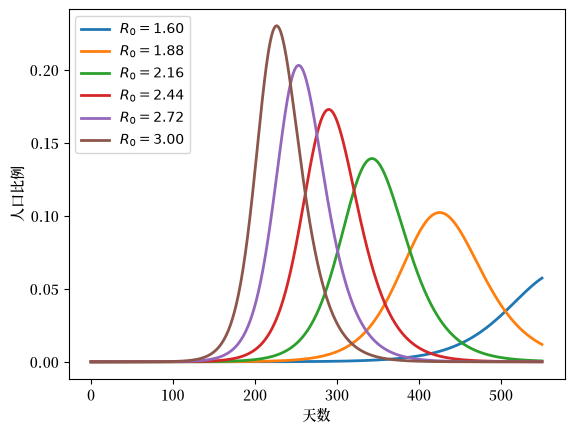

In [12]:
plot_paths(i_paths, labels, ylabel='人口比例')

正如预期的那样，较低的有效传播率会推迟感染高峰。

同时也会导致当前病例的峰值降低。

以下是累计病例数（占总人口的比例）：

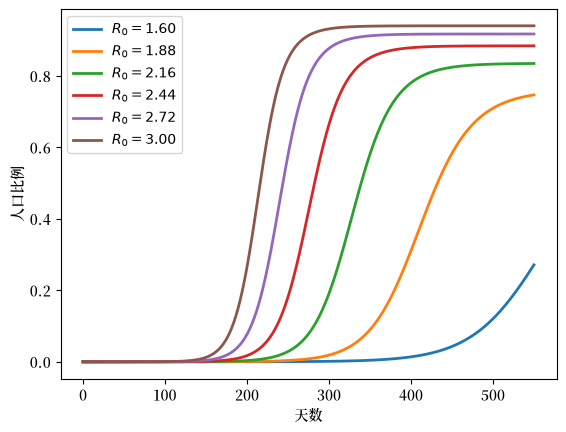

In [13]:
plot_paths(c_paths, labels, ylabel='人口比例')

### 实验2：改变缓解措施

让我们来看一个逐步实施缓解措施（例如社交距离）的场景。

以下是一个关于 `R0`随时间变化的函数规范。

In [14]:
def R0_mitigating(t, r0=3, η=1, r_bar=1.6):
    R0 = r0 * exp(- η * t) + (1 - exp(- η * t)) * r_bar
    return R0

`R0` 从 3 开始下降到 1.6。

这是由于逐步采取更严格的缓解措施所致。

参数 `η` 控制限制措施实施的速率或速度。

由于 $t$ 以天为单位计量，$\eta$ 以每天为单位计量，而其倒数 $1/\eta$ 则是调整周期。

下面的值分别对应于5天、10天、20天、50天和100天的调整周期：

In [15]:
η_vals = 1/5, 1/10, 1/20, 1/50, 1/100
labels = [fr'$\eta = {η:.2f}$' for η in η_vals]

以下是在这些不同速率下 `R0` 的时间路径：

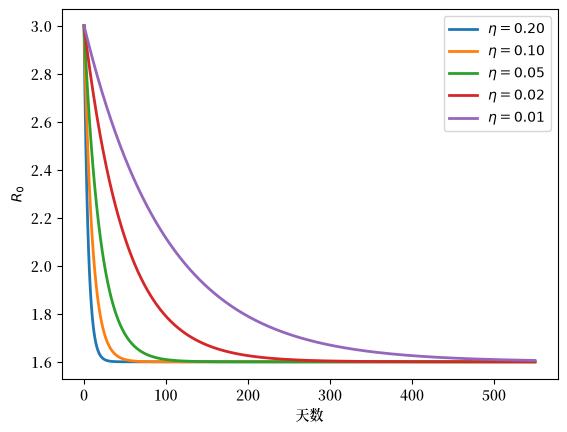

In [16]:
fig, ax = plt.subplots()

for η, label in zip(η_vals, labels):
    ax.plot(t_vec, R0_mitigating(t_vec, η=η), lw=2, label=label)

ax.set_xlabel('天数')
ax.set_ylabel('$R_0$')
ax.legend()
plt.show()

让我们计算感染者人数的时间路径：

In [17]:
i_paths, c_paths = [], []

for η in η_vals:
    R0 = lambda t: R0_mitigating(t, η=η)
    i_path, c_path = solve_path(R0, t_vec)
    i_paths.append(i_path)
    c_paths.append(c_path)

以下是不同场景下的当前案例：

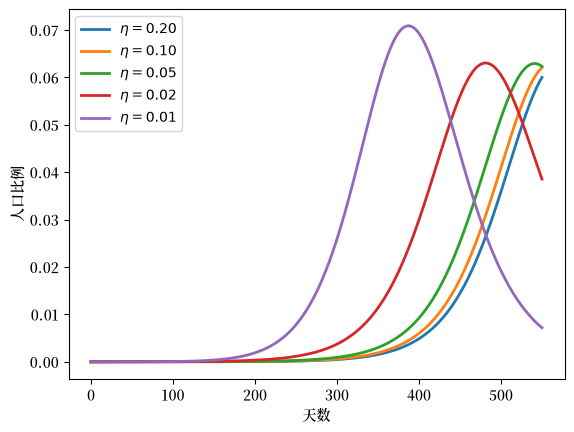

In [18]:
plot_paths(i_paths, labels, ylabel='人口比例')

以下是累计病例数（占总人口的比例）：

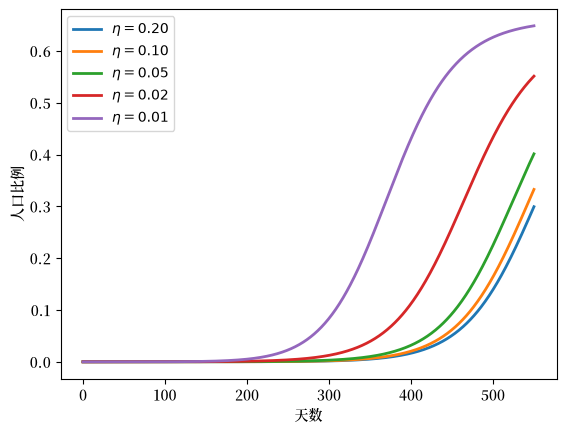

In [19]:
plot_paths(c_paths, labels, ylabel='人口比例')

更快实施缓解措施主要会推迟感染高峰，而对高峰的高度影响较小。

## 解除封锁

以下内容复现了 Andrew Atkeson 关于解除封锁时机的 [附加研究结果](https://drive.google.com/file/d/1uS7n-7zq5gfSgrL3S0HByExmpq4Bn3oh/view)。

我们对比两种解封方案：

1. $R_t = 0.5$持续30天，之后17个月$R_t = 2$。这相当于30天后解除封锁。
2. $R_t = 0.5$持续120天，之后14个月$R_t = 2$。这相当于4个月后解除封锁。

这里所考虑的参数设定模型初始时有25,000名活跃感染者，
以及75,000名已经暴露于病毒、即将具有传染性的人群。

In [20]:
# 初始条件
i_0 = 25_000 / pop_size
e_0 = 75_000 / pop_size
s_0 = 1 - i_0 - e_0
x_0 = s_0, e_0, i_0

让我们计算路径：

In [21]:
R0_paths = (lambda t: 0.5 if t < 30 else 2,
            lambda t: 0.5 if t < 120 else 2)

labels = [f'场景 {i}' for i in (1, 2)]

i_paths, c_paths = [], []

for R0 in R0_paths:
    i_path, c_path = solve_path(R0, t_vec, x_init=x_0)
    i_paths.append(i_path)
    c_paths.append(c_path)

这是具有活跃感染的人口比例：

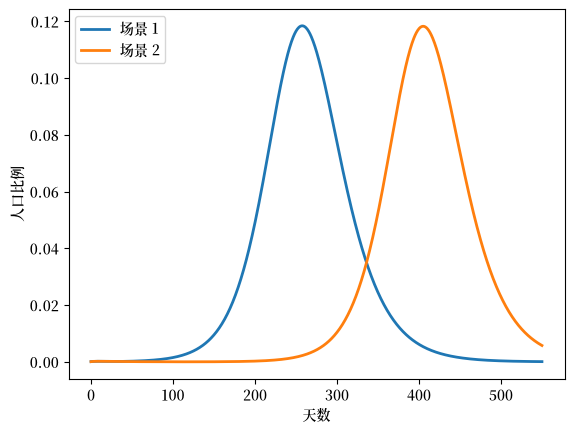

In [22]:
plot_paths(i_paths, labels, ylabel='人口比例')

两种场景下的感染高峰大致相同，但较长的封锁会推迟高峰的到来。

在这些场景下，死亡率会是怎样的呢？

假设1%的病例会导致死亡。

In [23]:
ν = 0.01

这是累计死亡人数：

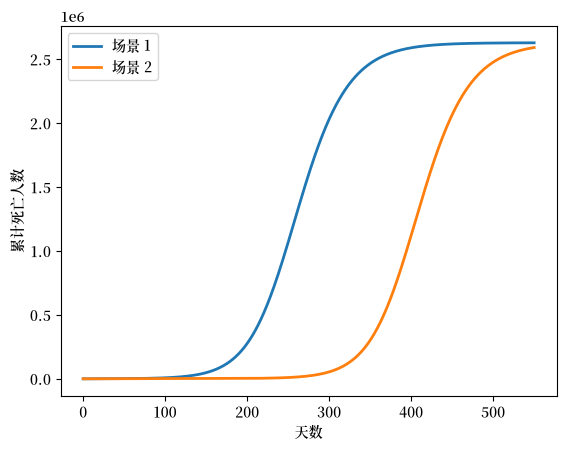

In [24]:
paths = [(c_path - i_path) * ν * pop_size
         for c_path, i_path in zip(c_paths, i_paths)]
plot_paths(paths, labels, ylabel='累计死亡人数')

这是每日死亡人数：

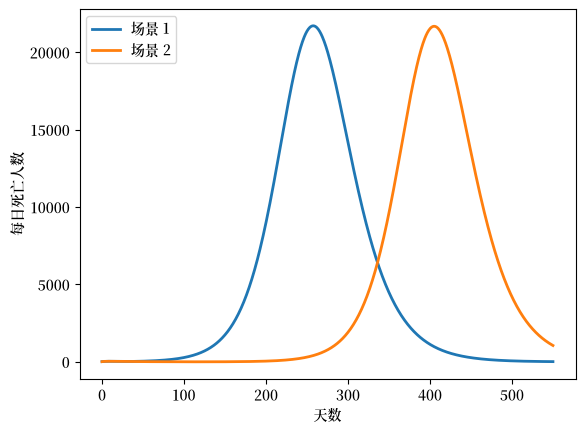

In [25]:
paths = [path * ν * γ * pop_size for path in i_paths]
plot_paths(paths, labels, ylabel='每日死亡人数')

如果能研制出疫苗，将曲线的峰值进一步推向未来，就可能减少累计死亡人数。